<div style="background-color: #f5f5f5; padding: 20px; border-radius: 10px; border: 1px solid #e0e0e0;">
<table style="width:100%; border:none;">
  <tbody><tr style="border:none;">
    <td style="width:20%; text-align:center; border:none; vertical-align:middle;">
      <img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="UI Logo" width="100">
    </td>
    <td style="width:60%; text-align:center; border:none; vertical-align:middle;">
      <h1 style="margin:0; color:#333;">University of Isfahan</h1>
      <h2 style="margin:0; color:#555; font-weight:normal;">Faculty of Mathematics and Statistics</h2>
      <br/>
      <hr style="border: 1px solid #ccc; margin-top:15px; margin-bottom:15px;">
      <h3 style="margin:0; color:#0056b3;">Third Practical Homework: Multi-Class Neural Network</h3>
      <br/>
      <h4 style="margin:0; font-size: 1.1em; color: #333; line-height: 1.6; margin-top: 15px; display: inline-block;">
        <strong>Course:</strong> Machine Learning<br>
        <strong>Instructor:</strong> Dr. Mohsen Alambardar<br>
        <strong>Semester:</strong> Fall 1404-1405
      </h4>
    </td>
    <td style="width:20%; text-align:center; border:none; vertical-align:middle;">
      <img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="UI Logo" width="100">
    </td>
  </tr>
</tbody></table>
</div>

<div style="background-color: #f5f5f5; border: 1px solid #f5f5f5; padding: 20px; border-radius: 10px; margin-top: 25px; margin-bottom: 25px;">
  
  <h3 style="text-align: center; margin-top: 0; color: #0056b3;">Student Information</h3>
  <p style="text-align: center; color: #555; margin-bottom: 20px; margin-top: 0;">
    Please fill in your details below.
  </p>

  <table style="width: 60%; margin-left: auto; margin-right: auto; border: none; font-size: 1.1em; color: #333;">
    <tbody>
      <tr>
        <td style="text-align: right; padding: 8px; width: 35%;"><strong>Student Name:</strong></td>
        <td style="text-align: left; padding: 8px;"><em>Hosna Soltanolkottabi</em></td> 
      </tr>
      <tr>
        <td style="text-align: right; padding: 8px;"><strong>Student ID:</strong></td>
        <td style="text-align: left; padding: 8px;"><em></em></td>  
      </tr>
    </tbody>
  </table>
  
</div>

# **HW3-P: Multi-Class Neural Network from Scratch**

Welcome! In the workshop, you built a 2-layer network to solve the binary XOR problem using a `sigmoid` activation. For this assignment, you will **adapt and extend your workshop code** to solve a 3-class problem.

**Our goal:** To build a multi-class classifier from scratch. This will require you to:
1.  Implement the **ReLU** activation function (a modern alternative to `sigmoid` for hidden layers).
2.  Implement the **Softmax** function for the output layer to handle multi-class probabilities.
3.  Implement the **Categorical Cross-Entropy** loss function to measure error.
4.  Adapt the backpropagation logic for the new activation and loss functions.
5.  Run experiments to see the effect of activation functions, network capacity, and learning rate.

--- 

## **1. Setup: Importing Libraries**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# This is a 'magic' command in Jupyter notebooks to make plots appear inline
%matplotlib inline

# Set default figure size
plt.rcParams['figure.figsize'] = (8, 6)
plt.style.use('ggplot')

--- 

## **2. Data Generation**

First, we need a dataset. We'll use the code below to generate a 3-class dataset. It consists of two non-linearly separable "moons" (Class 0 and 1) and a linearly separable "blob" (Class 2). `X` will be our feature matrix, and `y_onehot` will be the one-hot encoded labels, which is the format our loss function will need.

Dataset shape: (450, 2)
One-hot labels shape: (450, 3)


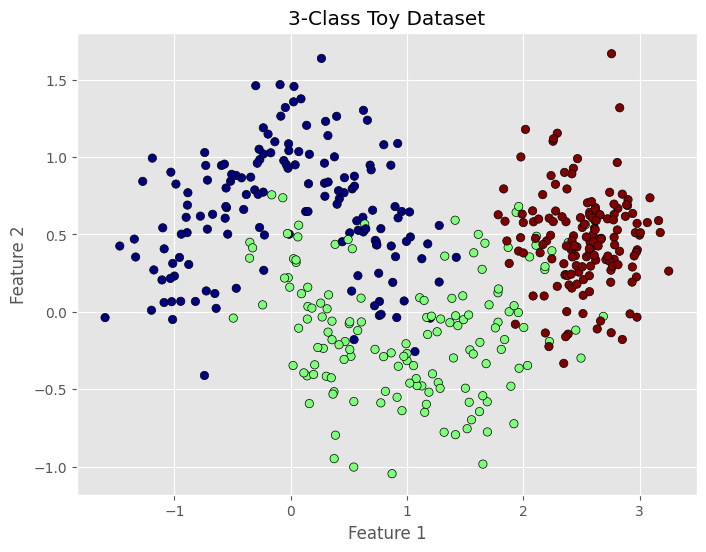

In [2]:
def load_dataset(n_samples=300):
    # Generate two "moons" for classes 0 and 1
    X_moons, y_moons = make_moons(n_samples=n_samples, noise=0.25, random_state=42)
    
    # Create a third, linearly separable "blob" for class 2
    X_blob = np.random.normal(loc=[2.5, 0.5], scale=0.3, size=(n_samples // 2, 2))
    y_blob = np.full(n_samples // 2, 2)
    
    # Combine the datasets
    X = np.vstack([X_moons, X_blob])
    y = np.hstack([y_moons, y_blob])
    
    # One-hot encode the labels
    n_classes = 3
    y_onehot = np.zeros((y.shape[0], n_classes))
    y_onehot[np.arange(y.shape[0]), y] = 1
    
    return X, y, y_onehot

# Load data
X, y_labels, y_onehot = load_dataset()
n_samples, n_features = X.shape
n_classes = y_onehot.shape[1]

print(f"Dataset shape: {X.shape}")
print(f"One-hot labels shape: {y_onehot.shape}")

# Plot data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_labels, cmap=plt.cm.jet, edgecolor='k')
plt.title('3-Class Toy Dataset')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

--- 

## **3. Implementing the Network Components**

Before we can build the training loop, we need to define our new component functions.

### **3.1 Activation Functions (ReLU and Sigmoid)**

You'll implement the **ReLU** function and its derivative. We also provide the `sigmoid` and `sigmoid_derivative` from the workshop, as you'll need them for Experiment 1.

In [3]:
def relu(z):
    # TODO: Implement the ReLU activation function
    # f(z) = max(0, z)
    return np.maximum(0, z)

def relu_derivative(z):
    # TODO: Implement the derivative of the ReLU function
    # f'(z) = 1 if z > 0, 0 otherwise
    return (z > 0).astype(int)

In [4]:
# Provided from workshop for Experiment 1
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)

### **3.2 Output and Loss Functions**

You now need to implement the **Softmax** function and the **Categorical Cross-Entropy** loss function.

In [5]:
def softmax(z):
    # TODO: Implement the Softmax function
    # For numerical stability, subtract the max value from z
    exp_scores = np.exp(z - np.max(z, axis=1, keepdims=True))
    # TODO: Normalize to get probabilities
    return exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

In [6]:
def calculate_loss(y_true, y_pred):
    # y_true is (n_samples, n_classes) (one-hot)
    # y_pred is (n_samples, n_classes) (probabilities from softmax)
    
    # TODO: Implement Categorical Cross-Entropy Loss
    
    # 1. Add a small epsilon to y_pred to prevent log(0)
    epsilon = 1e-15
    y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
    
    # 2. Calculate the sum of -y_true * log(y_pred) for all samples
    #    (Hint: np.sum can sum over the whole matrix)
    log_likelihood = -np.sum(y_true * np.log(y_pred_clipped))  # TODO: REPLACE THIS with your calculation
    
    # 3. Return the *average* loss per sample
    m = y_true.shape[0]
    return log_likelihood / m  # TODO: REPLACE THIS with your calculation

--- 

## **4. Building and Training the Model**

Now you will combine all the pieces into a `train` function. This will be very similar to the workshop, but you'll use your new functions.

**Network Architecture:**
* **Input:** 2 features
* **Hidden Layer:** `hidden_nodes` (we'll start with 10)
* **Output:** 3 features (for 3 classes)

In [7]:
def train(X, y_onehot, hidden_nodes, learning_rate, epochs, activation_fn, activation_grad_fn):
    """
    Trains a 2-layer neural network.
    
    Args:
        X: Input data (n_samples, n_features)
        y_onehot: One-hot encoded labels (n_samples, n_classes)
        hidden_nodes: Number of neurons in the hidden layer
        learning_rate: Step size for gradient descent
        epochs: Number of training iterations
        activation_fn: The activation function for the hidden layer (e.g., relu)
        activation_grad_fn: The derivative of the activation function (e.g., relu_derivative)
        
    Returns:
        A dictionary 'model' containing the trained W1, b1, W2, b2
        A list 'losses' containing the loss at each epoch
    """
    
    n_samples, n_features = X.shape
    n_classes = y_onehot.shape[1]
    
    # 1. Initialize Parameters
    np.random.seed(42)
    W1 = np.random.randn(n_features, hidden_nodes) * 0.01
    b1 = np.zeros((1, hidden_nodes))
    W2 = np.random.randn(hidden_nodes, n_classes) * 0.01
    b2 = np.zeros((1, n_classes))
    
    losses = []
    
    for i in range(epochs):
        # --- 2. FORWARD PASS ---
        
        # TODO: Calculate Hidden Layer output
        Z1 = X @ W1 + b1 # TODO: REPLACE THIS
        A1 = activation_fn(Z1) # TODO: REPLACE THIS
        
        # TODO: Calculate Output Layer scores and probabilities
        Z2 = A1 @ W2 + b2 # TODO: REPLACE THIS
        A2 = softmax(Z2) # TODO: REPLACE THIS
        
        # --- 3. CALCULATE LOSS ---
        loss = calculate_loss(y_onehot, A2)
        if i % 1000 == 0:
            losses.append(loss)
            
        # --- 4. BACKWARD PASS ---
        
        # TODO: Gradient for the Output Layer (Z2)
        # This is the key simplification for Softmax + CCE Loss!
        dZ2 = (A2 - y_onehot) / n_samples # TODO: REPLACE THIS
        
        # TODO: Gradients for W2 and b2
        dW2 = A1.T @ dZ2 # TODO: REPLACE THIS
        db2 = np.sum(dZ2, axis=0, keepdims=True) # TODO: REPLACE THIS
        
        # TODO: Propagate gradient to Hidden Layer (A1)
        dA1 = dZ2 @ W2.T # TODO: REPLACE THIS
        
        # TODO: Propagate gradient through the activation function derivative
        # (This is the dZ1 from the workshop)
        d_activation = activation_grad_fn(Z1) # TODO: REPLACE THIS
        dZ1 = dA1 * d_activation # TODO: REPLACE THIS
        
        # TODO: Gradients for W1 and b1
        dW1 = X.T @ dZ1 # TODO: REPLACE THIS
        db1 = np.sum(dZ1, axis=0, keepdims=True) # TODO: REPLACE THIS
        
        # --- 5. UPDATE PARAMETERS ---
        
        # TODO: Update W1, b1, W2, b2
        W1 = W1 - learning_rate * dW1 # TODO: REPLACE THIS
        b1 = b1 - learning_rate * db1 # TODO: REPLACE THIS
        W2 = W2 - learning_rate * dW2 # TODO: REPLACE THIS
        b2 = b2 - learning_rate * db2 # TODO: REPLACE THIS
        
    if epochs % 1000 != 0:
        losses.append(loss) # Add final loss
        
    print(f"Final loss after {epochs} epochs: {loss:.4f}")
    
    model = {'W1': W1, 'b1': b1, 'W2': W2, 'b2': b2}
    return model, losses

--- 

## **5. Initial Training and Visualization**

Let's train our main model. We will use:
* **Hidden Neurons:** 10
* **Learning Rate:** 0.1
* **Epochs:** 20,000
* **Activation:** ReLU

Training ReLU model...
Final loss after 20000 epochs: 0.1992


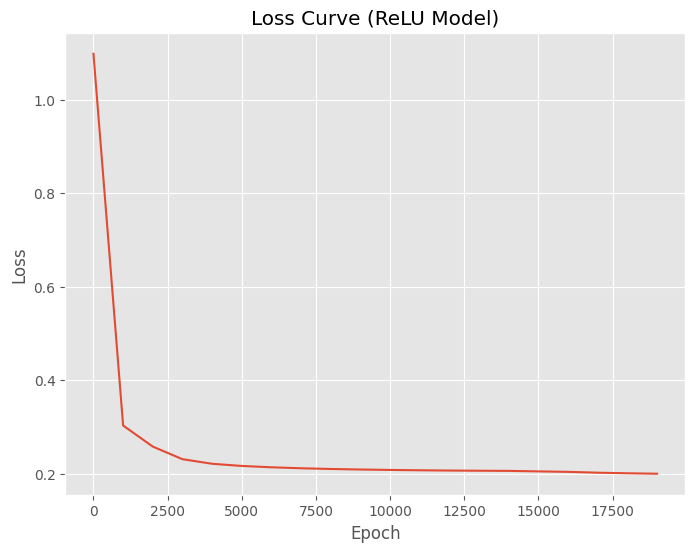

In [8]:
# Set hyperparameters
hidden_nodes = 10
learning_rate = 0.1
epochs = 20000

# Train the model with ReLU
print("Training ReLU model...")
relu_model, relu_losses = train(X, y_onehot, hidden_nodes, learning_rate, epochs, relu, relu_derivative)

# Plot the loss curve
loss_ticks = [i * 1000 for i in range(len(relu_losses))]
plt.plot(loss_ticks, relu_losses)
plt.title("Loss Curve (ReLU Model)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

### **Visualize the Decision Boundary**

Now, let's plot the decision boundary our network has learned. We will use an adapted version of the plotting function from the workshop.

This new `plot_decision_boundary` function is slightly different:
1.  It now takes an `activation_fn` (e.g., `relu` or `sigmoid`) as an argument, so we can reuse it in our experiments.
2.  To get the predicted class, it calculates the final scores `Z2` and then uses `np.argmax(Z2, axis=1)`. This finds the index (0, 1, or 2) of the highest score, which is the network's prediction. (Note: We don't need to run `softmax` because `np.argmax` on the raw scores gives the same result and is faster).
3.  We use `cmap=plt.cm.jet` in the plot, which is a color map suitable for 3 classes.

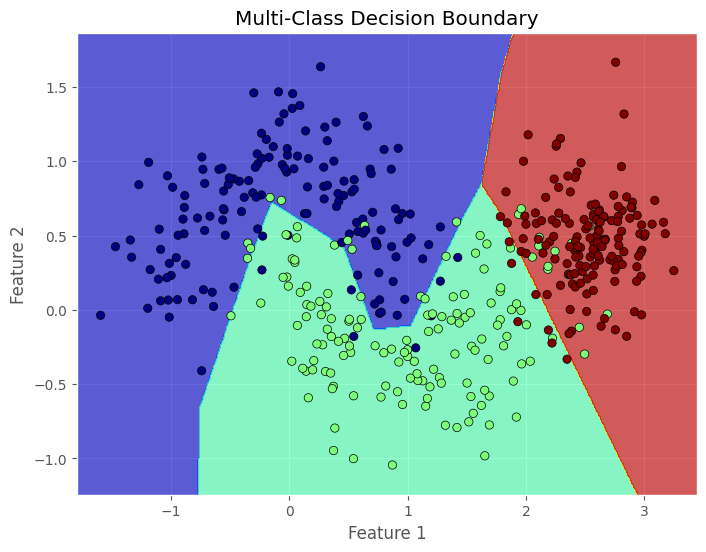

In [9]:
def plot_decision_boundary(model, X_data, y_data, activation_fn):
    # Set min and max values for the plot
    x_min, x_max = X_data[:, 0].min() - 0.2, X_data[:, 0].max() + 0.2
    y_min, y_max = X_data[:, 1].min() - 0.2, X_data[:, 1].max() + 0.2
    h = 0.01 # Step size in the mesh

    # Generate a grid of points
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    grid_points = np.c_[xx.ravel(), yy.ravel()] # Shape (n_points, 2)

    # --- Run the Forward Pass on ALL grid points ---
    Z1 = grid_points @ model['W1'] + model['b1']
    A1 = activation_fn(Z1)
    Z2 = A1 @ model['W2'] + model['b2']
    
    # --- Get predictions ---
    # Get the predicted class (0, 1, or 2) by finding the index of the highest score
    predictions = np.argmax(Z2, axis=1)
    predictions = predictions.reshape(xx.shape)

    # --- Plot the results ---
    plt.figure(figsize=(8, 6))
    cmap = plt.cm.jet # Colormap for 3 classes
    plt.contourf(xx, yy, predictions, cmap=cmap, alpha=0.6)

    # Plot the original data points on top
    plt.scatter(X_data[:, 0], X_data[:, 1], c=y_data, cmap=cmap, edgecolor='k')

    plt.title("Multi-Class Decision Boundary")
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.show()

# --- Run the function! ---
# We pass our trained relu_model, the data, and the relu function itself
plot_decision_boundary(relu_model, X, y_labels, relu)

--- 

## **6. Experiments and Analysis**

Now you will run the experiments to analyse a few different aspects of NNs.

### **Experiment 1: Activation Functions (ReLU vs. Sigmoid)**

Re-run the training, but this time use the **Sigmoid** activation function (from the workshop) in the hidden layer instead of ReLU. Plot the loss curves for both models on the same graph to compare their training speed.

Training Sigmoid model...
Final loss after 20000 epochs: 0.2197


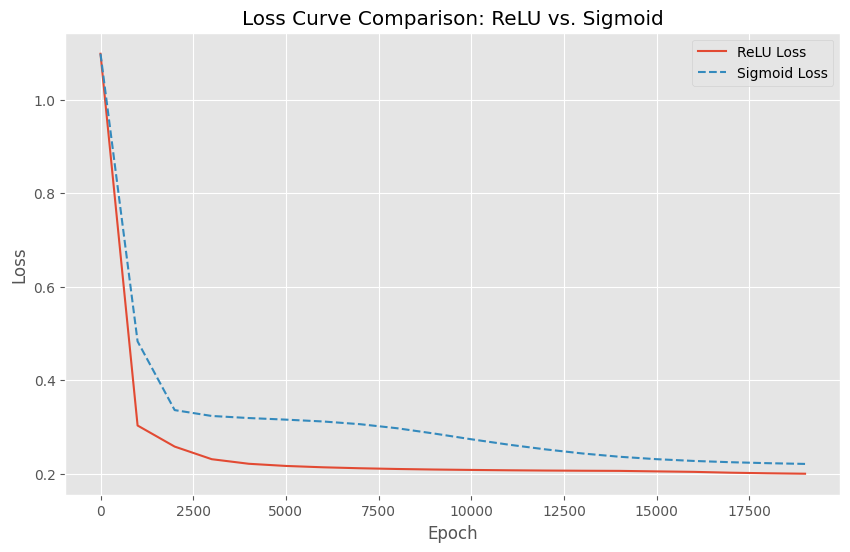

In [10]:
# Train the Sigmoid model
print("Training Sigmoid model...")
sigmoid_model, sigmoid_losses = train(X, y_onehot, hidden_nodes, learning_rate, epochs, sigmoid, sigmoid_derivative)

# Plot the loss curves together
plt.figure(figsize=(10, 6))
plt.plot(loss_ticks, relu_losses, label='ReLU Loss')
plt.plot(loss_ticks, sigmoid_losses, label='Sigmoid Loss', linestyle='--')
plt.title("Loss Curve Comparison: ReLU vs. Sigmoid")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

### **Analysis 1: ReLU vs. Sigmoid** `#TODO`

**Instructions:** Look at the loss curve plot above and answer the following:

1.  Which activation function (ReLU or Sigmoid) trained faster (i.e., reached a lower loss in fewer epochs)?
2.  Which function achieved a lower final loss?

**A quick note (optional):** 🤓 You probably noticed one function trained much faster! There's a famous reason for this. The `sigmoid` function's derivative becomes almost zero for large positive or negative inputs. This can "vanish" the gradient, causing the network to learn very slowly. This is known as the "**vanishing gradient problem**," and it's a key reason why ReLU is so popular in modern networks! You don't need to know the details right now, but it's a core concept in deep learning if you're curious.

**Your Analysis:**
<p dir="rtl">
1.تابع relu سریعتر مقدار تابع هزینه آن کم شده است.
2.تابع relu به مقدار هزینه کمتری در نهایت دست یافته است.
</p>

### **Experiment 2: Network Capacity (Number of Hidden Neurons)**

Train your **ReLU** network two times with different hidden layer sizes: **2 neurons** and **10 neurons** (your original). Plot the final decision boundary for both models.

Training model with 2 hidden neurons...
Final loss after 20000 epochs: 0.2942
Training model with 10 hidden neurons...
Final loss after 20000 epochs: 0.1992
Plotting decision boundaries...


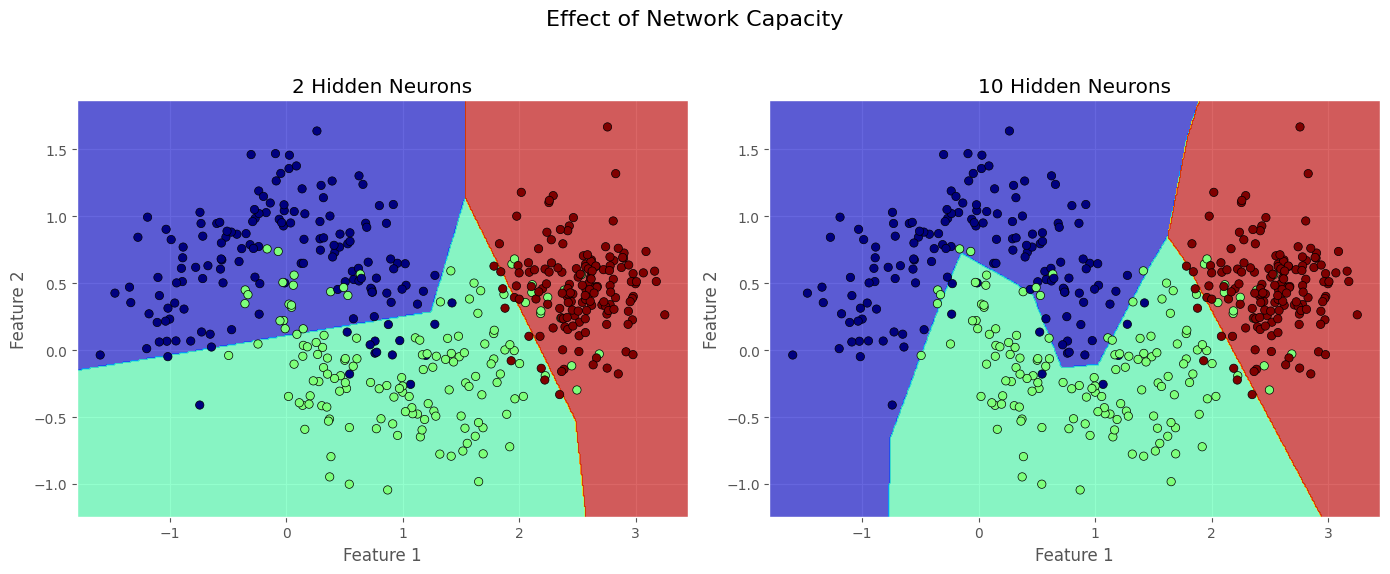

In [11]:
neuron_counts = [2, 10]
models = {}

for n in neuron_counts:
    print(f"Training model with {n} hidden neurons...")
    model, losses = train(X, y_onehot, n, learning_rate, epochs, relu, relu_derivative)
    models[n] = model

print("Plotting decision boundaries...")
plt.figure(figsize=(14, 6))
for i, n in enumerate(neuron_counts):
    ax = plt.subplot(1, len(neuron_counts), i + 1)
    
    # --- Copied plotting logic from before ---
    x_min, x_max = X[:, 0].min() - 0.2, X[:, 0].max() + 0.2
    y_min, y_max = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01), np.arange(y_min, y_max, 0.01))
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    
    model = models[n]
    Z1 = grid_points @ model['W1'] + model['b1']
    A1 = relu(Z1)
    Z2 = A1 @ model['W2'] + model['b2']
    predictions = np.argmax(Z2, axis=1)
    predictions = predictions.reshape(xx.shape)
    
    cmap = plt.cm.jet
    ax.contourf(xx, yy, predictions, cmap=cmap, alpha=0.6)
    ax.scatter(X[:, 0], X[:, 1], c=y_labels, cmap=cmap, edgecolor='k')
    ax.set_title(f"{n} Hidden Neurons")
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')

plt.suptitle('Effect of Network Capacity', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### **Analysis 2: Network Capacity** `#TODO`

**Instructions:** Look at the decision boundaries above.

1.  Describe the boundary for **2 neurons**. Does it successfully separate the 3 classes? This is an example of **underfitting**.
2.  Describe the boundary for **10 neurons**. Does this look like a good fit?

**Your Analysis:**
<p dir="rtl">
1.همانطور که در شکل مشخص است تعداد زیادی از داده ها(به ویژه داده های کلاس سبز) در کلاس های نادرست قرار دارند و این مرز تصمیم مناسب نیست.
2.با وجود این که تعدادی از داده های آموزشی در کلاس درست دسته بندی نشده اند اما این مرز تصمیم، مرز تصمیم مناسبی است چون به درستی شکل های مربوط به هلال ماه رو مرزبندی کرده و برای داده های جدید با احتمال بالایی به درستی پیش بینی انجام خواهد داد.
</p>

### **Experiment 3: Learning Rate**

Using your original 10-neuron ReLU network, train it three times with different learning rates: `0.001` (Too Small), `0.1` (Your original), and `5.0` (Too Large). Plot the loss curves for all three.

Training model with LR=0.001...
Final loss after 20000 epochs: 0.6297
Training model with LR=0.1...
Final loss after 20000 epochs: 0.1992
Training model with LR=5.0...
Final loss after 20000 epochs: 0.6296


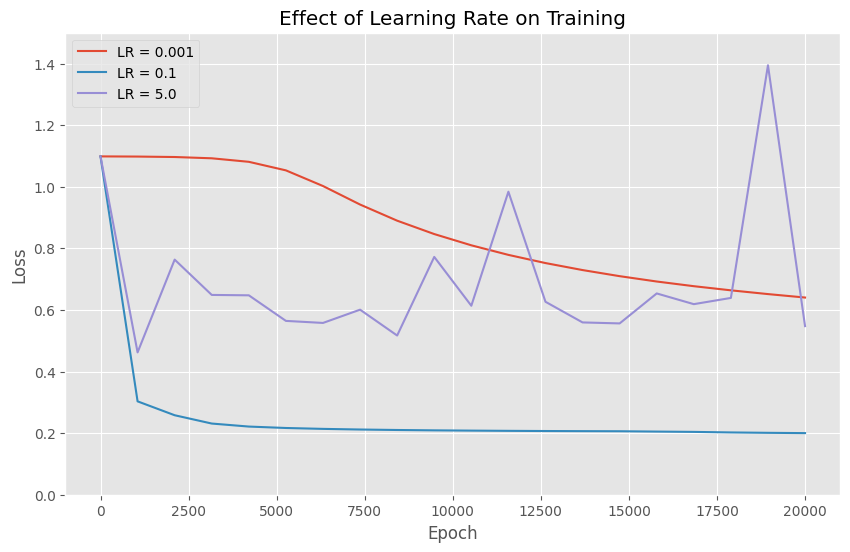

In [12]:
learning_rates = [0.001, 0.1, 5.0]
lr_losses = {}

for lr in learning_rates:
    print(f"Training model with LR={lr}...")
    # Note: We use fewer epochs for the large LR to prevent it from exploding too much
    e = 5000 if lr == 1.5 else 20000
    model, losses = train(X, y_onehot, hidden_nodes, lr, e, relu, relu_derivative)
    lr_losses[lr] = losses

plt.figure(figsize=(10, 6))
for lr, losses in lr_losses.items():
    e = 5000 if lr == 1.5 else 20000
    ticks = np.linspace(0, e, len(losses))
    plt.plot(ticks, losses, label=f"LR = {lr}")

plt.title("Effect of Learning Rate on Training")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.ylim(0, 1.5) # Zoom in on the loss
plt.show()

### **Analysis 3: Learning Rate** `#TODO`

**Instructions:** Look at the loss curve plot above.

1.  Describe the curve for `LR = 0.001`. Is it training well? 
2.  Describe the curve for `LR = 0.1`. This is our "good" baseline.
3.  Describe the curve for `LR = 5.0`. What happened? Notice that it converged *very* quickly, but to a *much higher* loss than `LR = 0.1`. This is a classic example of a "too large" learning rate. Why do you think this happens?

**Your Analysis:**
<p dir="rtl">
1.همانطور که در نمودار مشخص است با وجود این که مقدار هزینه در حال کاهش است اما این کند است یا به عبارت دیگر سرعت همگرایی کم است که نتیجه کوچک بودن نرخ یادگیری است.
2.همانطور که دیده میشود شیب کاهش هزینه خوب بود و پس از5000 تکرار مقدار تابع هزینه به حدود 0.2 میرسد.
3.نمودار در ابتدا با شیب خوبی هزینه رو کاهش داده اما در نقطه ای بالا تر از جایی که در نمودار آبی داریم این شیب تغییر پیدا کرده و از آنجا به بعد رفتار نوسانی دارد این موضوع به خاطر overshoot شدن است.
</p>

<div style="background-color: #e6f7ff; padding: 20px; border-radius: 10px; border: 1px solid #b3e0ff; text-align: center;">
  <h3 style="margin:0; color:#0056b3;">Congratulations!</h3>
  <p style="color:#333; font-size: 1.1em;">You have completed the third practical homework.</p>
</div>